## 06A Baseline Model for Claims

#### Purpose
- Develop the baseline model for claims (`CLAIM_IN_TERM` = 1 if the policy-year has at least one flood claim during its term).
- The baseline is a **logistic regression**: a simple, transparent model that gives a probability for every policy-year. Every later model (07a, gradient boosting) must beat it, and both must beat two naive rules.

#### Why logistic regression first
Logistic regression is the standard first model for a yes/no outcome in insurance and credit risk. Its coefficients can be read as odds ratios, it gives probabilities on the real claim scale, and it shows how much of the signal a straight-line (linear) model can capture before we try anything more complex.

#### How we judge the models
We look at the model in two ways:
1. **As a classifier** (the view from our course): **confusion matrices** with accuracy, precision, recall and F1, and the **ROC curve** with its AUC. A confusion matrix needs a cut-off; with about 1% claims, the default 0.5 flags almost nobody, so we also use cut-offs that flag the riskiest 5%, 10% and 20% of policy-years.
2. **As a probability model:** **log loss**, **Brier score** and **calibration** (predicted vs actual rate). The model's use (expected claims and pricing) needs the probabilities themselves to be right, which a confusion matrix cannot show. Log loss is also what we tune on (Step 4.0), because it is the quantity logistic regression minimizes.

#### Steps:
1. Load the features and show the time split (development, in-time, out-of-time)
2. Naive benchmarks (base rate, segment rate)
3. Preprocessing pipeline
4. Tune with time-based folds (log loss), then train logistic regression on every training row
5. Out-of-time test results: log loss, Brier score, ROC-AUC, calibration, confusion matrices, ROC curve
6. Coefficient interpretation
7. Save the model and results

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III. 

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-16

### Section 0. Load the libraries and working directory
Use the same setup cell as notebook 02 (repo root, data folders, reports folder), so the notebook runs on every teammate's machine.

#### 0.1 Imports, paths and random seed

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.paths import DOCS, INTERIM, PROCESSED, RAW, REPORTS, ensure_dirs
from src.db import connect, scalar
from src.dq import CleaningLog
from src.features import apply_fixed_rules
from src.modeling import QuantileClipper
pd.options.display.float_format = "{:,.4g}".format     # 4 significant digits, so small rates and alphas stay readable

ensure_dirs()

### Section 1. Load the features and split

#### 1.1 Load the claim modeling table
We load the claim population one split at a time: **train** (2014–2020) to fit and **test** (2021–2022) to evaluate. **Validation** (2023 to Aug 2024) stays untouched until notebook 08. The training split is read in chunks, so the 27.5M rows never have to fit in memory at once.

The time split is shown in Step 1.2.

**Place features are excluded here.** Rainfall, ACS, latitude/longitude and BFE features reversed direction between the training and test years (notebook 05, Q7), so the model would learn where the 2014–2020 floods happened rather than a lasting risk. They describe *where* the 2014–2020 floods happened, not a lasting risk.

In [2]:
# Step 1.1 Settings and the chunk loader for the claim population
SEED = 42
TARGET = "CLAIM_IN_TERM"
ID_COLS = ["period_id", "period_year"]
N_CHUNKS = 28              # the 27.5M training rows are read in 28 chunks of about 1M rows

# The features we use, their kind and their missing-value plan, from notebook 05
plan = pd.read_csv(DOCS / "feature_plan.csv")
plan = plan[plan["use"]]

# Place features: in 2014-2020 they mostly mark where the big storms hit (Harvey in Texas), and they reverse
# in 2021-2022 (notebook 05, Q7). Set to [] to use them.
PLACE_FEATURES = [f for f in plan["feature"]
                  if f.startswith(("precip_", "heavy_rain", "acs_")) or f in ("latitude", "longitude", "base_flood_elevation")]
EXCLUDE = PLACE_FEATURES
plan = plan[~plan["feature"].isin(EXCLUDE)]

FEATS = plan["feature"].tolist()
NUMS = plan.loc[plan["kind"] == "num", "feature"].tolist()
CATS = plan.loc[plan["kind"] == "cat", "feature"].tolist()
FLAGS = plan.loc[plan["kind"] == "flag", "feature"].tolist()
print(f"{len(FEATS)} features: {len(NUMS)} numbers, {len(CATS)} categories, {len(FLAGS)} flags")

con = connect(db_path=None, memory_limit="4GB")
con.execute(f'''CREATE OR REPLACE VIEW claim_pop AS
                SELECT * FROM read_parquet('{PROCESSED / "features.parquet"}') WHERE in_pop_claim''')

def prepare(df):
    '''Fixed clean-up rules (notebook 05) and compact types; returns X, y, ids.'''
    df = apply_fixed_rules(df)
    df[NUMS] = df[NUMS].astype("float32")
    df[FLAGS] = df[FLAGS].astype("float32")
    cats = df[CATS].astype("string")
    df[CATS] = cats.astype(object).where(cats.notna(), np.nan)     # plain text, NaN where missing
    return df[FEATS], df[TARGET].astype("int8"), df[ID_COLS]

def load_rows(split, where="TRUE", sample_rows=None, seed=SEED):
    '''Rows of one split. where: extra filter; sample_rows: a random sample of that size (same rows for the same seed).'''
    query = f"SELECT {', '.join(ID_COLS + FEATS)}, {TARGET} FROM claim_pop WHERE split = '{split}' AND {where}"
    if sample_rows:
        query = f"SELECT * FROM ({query}) USING SAMPLE reservoir({sample_rows} ROWS) REPEATABLE ({seed})"
    return prepare(con.sql(query).df())

def chunk_filter(k, epoch):
    '''Chunk k of N_CHUNKS: a hash of the row id, different for every epoch, so each chunk is a random mix of
    states and years (the file itself is ordered by state, which would mislead the model).'''
    return f"hash(period_id || '{SEED}-{epoch}') % {N_CHUNKS} = {k}"

52 features: 27 numbers, 12 categories, 13 flags


#### 1.2 The time split: development, in-time and out-of-time samples
We never split at random: the model is trained on earlier years and judged on later years, the way it will be used. In model-validation terms:

| Sample | Years | Validation term | Use |
|---|---|---|---|
| Train | 2014–2020 | **Development sample** | Fit the preprocessing and the model |
| Rolling folds inside train | learn on the years before, check on 2017, 2018, 2019, 2020 | **In-time validation** (rolling origin) | Choose `alpha` and `eta0` (Step 4.0) |
| Test | 2021–2022 | **Out-of-time 1 (OOT1)** | Compare the model with the benchmarks; choose between models |
| Validation | 2023 – Aug 2024 | **Out-of-time 2 (OOT2)**, final holdout | One final check in notebook 08 |

- **In-time** checks stay inside the development years. Our folds always check on a *later* year than they learn from, so even the tuning never uses the future.
- **Out-of-time** checks use years the model has never seen. They answer the real question: do the probabilities still hold when the conditions change (new storms, premium changes under Risk Rating 2.0 from late 2021)?
- **OOT1 is used for decisions** (which model, which settings), so it is no longer fully independent once we have looked at it. **OOT2 is opened only once**, in notebook 08, to give an unbiased final result.

The graph shows the number of policy-years and the claim rate per year, then which years each step learns from and checks on. 2024 runs only to August.

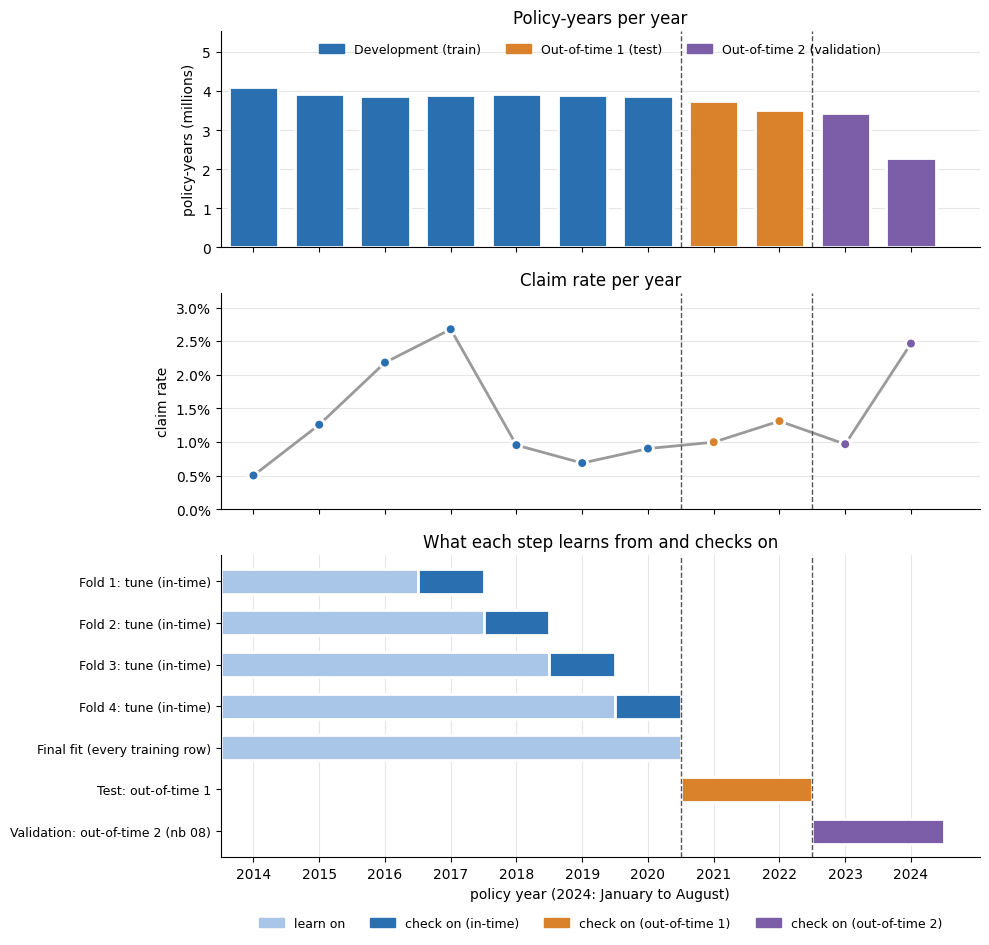

,first_year,last_year,policy_years,claim_rate
split,,,,
Development (train),2014,2020,"27,496,820",1.301%
Out-of-time 1 (test),2021,2022,"7,275,717",1.149%
Out-of-time 2 (validation),2023,2024,"5,724,790",1.564%


In [3]:
# Step 1.2 The time split as a graph: policy-years and claim rate per year, and what each step learns from and checks on
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

by_year = con.sql(f'''
    SELECT period_year AS year, 
           split, 
           COUNT(*) AS policy_years, 
           AVG(CAST({TARGET} AS DOUBLE)) AS rate
    FROM claim_pop 
    GROUP BY ALL 
    ORDER BY year
''').df()

SPLIT_NAME = {"train": "Development (train)", "test": "Out-of-time 1 (test)", "valid": "Out-of-time 2 (validation)"}
COLOR = {"train": "#2a6fb0", "learn": "#a9c6e8", "check": "#2a6fb0", "test": "#d9822b", "valid": "#7b5ea7"}
years = by_year["year"].to_numpy()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9.5), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1.4]})

# (a) policy-years per year, coloured by split
ax1.bar(years, by_year["policy_years"] / 1e6, width=0.75, color=by_year["split"].map(COLOR), edgecolor="white", linewidth=2)
ax1.set(title="Policy-years per year", ylabel="policy-years (millions)", ylim=(0, by_year["policy_years"].max() / 1e6 * 1.35))
ax1.legend(handles=[Patch(color=COLOR[s], label=n) for s, n in SPLIT_NAME.items()], frameon=False, loc="upper center", ncol=3, fontsize=9)

# (b) claim rate per year: how much the outcome itself moves from year to year
ax2.plot(years, by_year["rate"], color="#9a9a9a", linewidth=2, zorder=1)
ax2.scatter(years, by_year["rate"], c=by_year["split"].map(COLOR), s=60, edgecolor="white", linewidth=2, zorder=2)
ax2.set(title="Claim rate per year", ylabel="claim rate", ylim=(0, by_year["rate"].max() * 1.2))
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))

# (c) which years each step learns from and checks on
scheme = [(f"Fold {i + 1}: tune (in-time)", [(2014, y - 1, "learn"), (y, y, "check")]) for i, y in enumerate(range(2017, 2021))]
scheme += [("Final fit (every training row)", [(2014, 2020, "learn")]),
           ("Test: out-of-time 1", [(2021, 2022, "test")]),
           ("Validation: out-of-time 2 (nb 08)", [(2023, 2024, "valid")])]
for row, (label, spans) in enumerate(scheme):
    for start, end, kind in spans:
        ax3.barh(row, end - start + 1, left=start - 0.5, height=0.6, color=COLOR[kind], edgecolor="white", linewidth=2)
ax3.set_yticks(range(len(scheme)), [label for label, _ in scheme], fontsize=9)
ax3.invert_yaxis()
ax3.set(title="What each step learns from and checks on", xlabel="policy year (2024: January to August)")
ax3.legend(handles=[Patch(color=COLOR["learn"], label="learn on"), Patch(color=COLOR["check"], label="check on (in-time)"),
                    Patch(color=COLOR["test"], label="check on (out-of-time 1)"),
                    Patch(color=COLOR["valid"], label="check on (out-of-time 2)")],
           frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9, ncol=4)

for ax in (ax1, ax2, ax3):
    for edge in (2020.5, 2022.5):                       # where the development years end and each out-of-time period starts
        ax.axvline(edge, color="#555555", linewidth=1, linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y" if ax is not ax3 else "x", color="#e6e6e6")
    ax.set_axisbelow(True)
ax3.set_xticks(years)
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_time_split.png", dpi=150)
plt.show()

summary = (by_year.assign(n=by_year["rate"] * by_year["policy_years"])
                  .groupby("split", sort=False)
                  .agg(first_year=("year", "min"), last_year=("year", "max"), policy_years=("policy_years", "sum"), n=("n", "sum")))
summary["claim_rate"] = summary.pop("n") / summary["policy_years"]
summary.rename(index=SPLIT_NAME).style.format({"policy_years": "{:,}", "claim_rate": "{:.3%}"})

### Section 2. Naive benchmark
Every model must beat this.

#### 2.1 Naive benchmarks
Two simple predictions, learned on the training split, that every model must beat:

**1. Base rate:** every policy-year gets the training claim rate.
$$\hat{p}_i = \bar{y}_{\text{train}} = \frac{1}{n_{\text{train}}}\sum_{j \in \text{train}} y_j$$
It is right on average but gives every policy-year the same probability: the floor for "no information".

**2. Segment rate:** every policy-year gets the training claim rate of its segment *s* = zone group × "had an earlier claim".
$$\hat{p}_i = \bar{y}_{s(i)} = \frac{\sum_{j \in \text{train},\, s(j)=s(i)} y_j}{n_{s(i)}}$$
This is a rule an underwriter could build from a pivot table. If the logistic regression cannot beat it, the extra 60+ features add nothing.

We record their log loss and Brier score on the **test** split (2021–2022).

In [4]:
# Step 2.1 Naive benchmarks, learned on the training split only
# (1) base rate: the training claim rate for every row
# (2) segment rate: the training claim rate of each zone group x "had an earlier claim" segment
from sklearn.metrics import brier_score_loss, log_loss

base_rate = scalar(con, f"SELECT AVG(CAST({TARGET} AS DOUBLE)) FROM claim_pop WHERE split = 'train'")
segment_rates = con.sql(f'''
    SELECT CASE WHEN zone_group = 'UNKNOWN' THEN 'D' ELSE zone_group END AS zone_group,   -- same merge as apply_fixed_rules
           CAST(COALESCE(had_prior_claim, FALSE) AS INTEGER)               AS had_prior_claim,
           COUNT(*)                                                        AS train_rows,
           AVG(CAST({TARGET} AS DOUBLE))                                    AS segment_rate
    FROM claim_pop 
    WHERE split = 'train'
    GROUP BY ALL 
    ORDER BY segment_rate DESC
''').df()
print(f"training base rate: {base_rate:.4%}")
segment_rates.style.format({"train_rows": "{:,}", "segment_rate": "{:.3%}"})

training base rate: 1.3013%


,zone_group,had_prior_claim,train_rows,segment_rate
0,D,1,584,7.534%
1,X,1,"531,031",3.593%
2,V,1,"51,447",3.242%
3,A,1,"1,493,207",2.969%
4,V,0,"302,902",1.912%
5,A,0,"12,343,445",1.401%
6,D,0,"16,123",0.924%
7,X,0,"12,758,081",0.892%


### Section 3. Preprocessing pipeline

#### 3.1 Build the pipeline
Imputation, capping, scaling and encoding inside one scikit-learn `ColumnTransformer`, **fitted on training data only** (a 1M-row sample). The test and validation rows are only *transformed* with the medians, caps and categories learned on train, so no information leaks from the future.

Each feature follows the missing-value plan from notebook 05 (Section 6):

| Group | Missing values | Extra column | Example |
|---|---|---|---|
| Fill 0 + flag | 0 | `missingindicator_…` (1 = was missing) | first-term premium change |
| Fill 99 | 99 | none | years since the last claim (99 = never) |
| Median + flag | training median | missing flag | features where missing means something |
| Median, no flag | training median | none | tenure, ACS, and the features whose missingness leaks the target (5.2d) |
| Categories | `"(missing)"` | one-hot columns | zone group, occupancy, foundation |
| Flags (0/1) | 0 | missing flag | `mandatory_purchase`, `in_sfha` |

**Capping (`QuantileClipper`):** each number is limited to its training 1st and 99th percentile, so a few extreme values (such as a $10M building) cannot dominate the coefficients:

$$x' = \min\big(\max(x,\; q_{0.01}),\; q_{0.99}\big)$$

**Scaling (`StandardScaler`):** each number is centred and divided by its standard deviation (both from train):
$$z = \frac{x' - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
Scaling matters here for two reasons: stochastic gradient descent converges much faster when all features are on the same scale, and the L2 penalty treats every coefficient equally only if the features are comparable. It also makes the coefficients comparable: each one is the effect of **one standard deviation**.

**One-hot encoding:** each category becomes a 0/1 column. Categories seen in fewer rows are grouped into one "infrequent" column (at most 16 columns per feature), and a category that first appears in the test years goes to that same column instead of causing an error.

In [5]:
# Step 3.1 Preprocessing, fitted on a 1M-row sample of train (medians, caps, scaling and categories)
import time
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.modeling import QuantileClipper          # in src/, so the saved model can be loaded in other notebooks

# The numbers, grouped by their missing-value plan (6.1 in notebook 05)
mp = plan.set_index("feature")["missing_plan"]
num_fill0 = [f for f in NUMS if mp[f].startswith("fill 0")]                    # first term: 0 and a flag
num_fill99 = [f for f in NUMS if mp[f].startswith("fill 99")]                  # no earlier claim: 99
num_flag = [f for f in NUMS if mp[f].startswith("median (train) + missing flag")]
num_noflag = [f for f in NUMS if f not in num_fill0 + num_fill99 + num_flag]  # median, no flag (incl. the leak cases)

def numbers(imputer):
    return make_pipeline(imputer, QuantileClipper(), StandardScaler())

preprocess = ColumnTransformer([
    ("num_fill0", numbers(SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)), num_fill0),
    ("num_fill99", numbers(SimpleImputer(strategy="constant", fill_value=99)), num_fill99),
    ("num_flag", numbers(SimpleImputer(strategy="median", add_indicator=True)), num_flag),
    ("num_noflag", numbers(SimpleImputer(strategy="median")), num_noflag),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="(missing)"),
                          OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=16,
                                        sparse_output=False, dtype=np.float32)), CATS),
    ("flag", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), FLAGS),
], verbose_feature_names_out=False)

t0 = time.time()
X_fit, y_fit, _ = load_rows("train", sample_rows=1_000_000)
preprocess.fit(X_fit)
n_cols = len(preprocess.get_feature_names_out())
print(f"preprocessing fitted on {len(X_fit):,} rows in {time.time() - t0:.0f} s: {len(FEATS)} features -> {n_cols} model columns")

preprocessing fitted on 1,000,000 rows in 47 s: 52 features -> 161 model columns


In [6]:
# Step 3.2 Check: what the model sees (on 5,000 rows of the fitting sample)
Z = preprocess.transform(X_fit.iloc[:5000])
cols = preprocess.get_feature_names_out()
print(f"model columns: {Z.shape[1]}; missing values left after preprocessing: {int(np.isnan(Z).sum())}")

summary = pd.DataFrame(
    [{"group": name, "input features": len(feats),
      "model columns": len(preprocess.named_transformers_[name].get_feature_names_out(feats))}
     for name, _, feats in preprocess.transformers_ if name != "remainder"])
display(summary)

# Numbers should now have mean about 0 and standard deviation about 1; one-hot and flags are 0/1
scaled = [c for c in cols if c in NUMS]
idx = [list(cols).index(c) for c in scaled]
print(f"{len(scaled)} scaled numbers: mean {Z[:, idx].mean():.3f}, average std {Z[:, idx].std(axis=0).mean():.3f}")
del X_fit, y_fit, Z

model columns: 161; missing values left after preprocessing: 0


,group,input features,model columns
0,num_fill0,3,6
1,num_fill99,1,1
2,num_flag,3,6
3,num_noflag,20,20
4,cat,12,114
5,flag,13,14


27 scaled numbers: mean 0.002, average std 0.990


### Section 4. Logistic regression

#### 4.0 Tune with time-based folds (in-time validation)
Two settings must be chosen before training:

- **`alpha`**: the strength of the L2 penalty (Step 4.1). Larger values shrink the coefficients towards 0 and protect against overfitting.
- **`eta0`**: the starting step size of gradient descent. Too large and the training diverges; too small and it barely moves.

We try every combination (`GridSearchCV`, 3 × 2 = 6 settings) with **rolling-origin folds** (the in-time rows of the graph in Step 1.2): each fold learns on the years before and checks on the next year.

| Fold | Learn on | Check on |
|---|---|---|
| 1 | 2014–2016 | 2017 |
| 2 | 2014–2017 | 2018 |
| 3 | 2014–2018 | 2019 |
| 4 | 2014–2019 | 2020 |

**The best setting has the lowest mean log loss across the four folds.** Log loss is the quantity the model minimizes (Step 4.1) and it judges the probabilities themselves, so we tune for the same thing we report. We also look at the spread between years: a setting that wins on average but swings a lot from year to year is less trustworthy. Tuning uses a 1.5M-row sample of the training split; the test and validation years are not used.

In [7]:
# Step 4.0 Tune the penalty and step size with time-based folds, on a sample of train
from sklearn.base import clone
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

TUNE_ROWS = 1_500_000      # random rows from 2014-2020 (same rows every run)
X_tune, y_tune, ids_tune = load_rows("train", sample_rows=TUNE_ROWS)

# Rolling-origin folds (notebook 04): train on every year before, check on the next year.
# The first check year is 2017, so every fold has at least 3 years to learn from.
years = ids_tune["period_year"].to_numpy()
folds = [(np.where(years < y)[0], np.where(years == y)[0]) for y in range(2017, 2021)]
for (tr, te), y in zip(folds, range(2017, 2021)):
    print(f"fold checking {y}: learn on {len(tr):,} rows ({years[tr].min()}-{years[tr].max()}), check on {len(te):,}")

pipe = make_pipeline(clone(preprocess),          # preprocessing is refitted inside every fold
                     SGDClassifier(loss="log_loss", learning_rate="invscaling", power_t=0.25,
                                   average=True, max_iter=5, tol=None, random_state=SEED))
param_grid = {
    "sgdclassifier__alpha": [1e-6, 1e-5, 1e-4],  # L2 penalty
    "sgdclassifier__eta0": [0.001, 0.01],        # starting step size
}
search = GridSearchCV(pipe, param_grid, cv=folds,
                      scoring={"log_loss": "neg_log_loss", "brier": "neg_brier_score"},
                      refit=False,               # the final model is trained on every row, chunk by chunk (Step 4.1)
                      n_jobs=1, verbose=1)       # one job: parallel jobs fail on Python 3.14 with a class defined in the notebook
t0 = time.time()
search.fit(X_tune, y_tune)
print(f"done in {(time.time() - t0) / 60:.1f} min")

# scikit-learn reports the scores negated (higher = better); we turn them back into losses (lower = better)
cv = pd.DataFrame(search.cv_results_)
tuning = pd.DataFrame({
    "alpha": cv["param_sgdclassifier__alpha"].astype(float),
    "eta0": cv["param_sgdclassifier__eta0"].astype(float),
    "mean_log_loss": -cv["mean_test_log_loss"],
    "std_log_loss": cv["std_test_log_loss"],
    "mean_brier": -cv["mean_test_brier"],
    **{f"log_loss_{y}": -cv[f"split{i}_test_log_loss"] for i, y in enumerate(range(2017, 2021))},
}).sort_values("mean_log_loss").reset_index(drop=True)
best = tuning.iloc[0]
BEST_ALPHA, BEST_ETA0 = float(best["alpha"]), float(best["eta0"])
print(f"best (lowest mean log loss): alpha={BEST_ALPHA}, eta0={BEST_ETA0}")
tuning.style.format({"alpha": "{:g}", "eta0": "{:g}", "mean_brier": "{:.5f}"}, precision=5)

fold checking 2017: learn on 649,555 rows (2014-2016), check on 212,862
fold checking 2018: learn on 862,417 rows (2014-2017), check on 214,026
fold checking 2019: learn on 1,076,443 rows (2014-2018), check on 212,792
fold checking 2020: learn on 1,289,235 rows (2014-2019), check on 210,765
Fitting 4 folds for each of 6 candidates, totalling 24 fits
done in 5.1 min
best (lowest mean log loss): alpha=1e-06, eta0=0.001


,alpha,eta0,mean_log_loss,std_log_loss,mean_brier,log_loss_2017,log_loss_2018,log_loss_2019,log_loss_2020
0,1e-06,0.001,0.06934,0.03321,0.01276,0.12624,0.05689,0.04317,0.05105
1,1e-05,0.001,0.06934,0.03321,0.01276,0.12624,0.05689,0.04317,0.05106
2,0.0001,0.001,0.06934,0.03319,0.01276,0.12621,0.05690,0.04319,0.05107
3,0.0001,0.01,0.06953,0.03363,0.01278,0.12706,0.05797,0.04302,0.05009
4,1e-05,0.01,0.06956,0.03368,0.01278,0.12716,0.05800,0.04300,0.05007
5,1e-06,0.01,0.06956,0.03368,0.01278,0.12716,0.05800,0.04300,0.05007


#### 4.1 Fit on every training row

**The model.** Logistic regression gives the probability of a claim as a function of the features $\mathbf{x}_i$:
$$p_i = P(y_i = 1 \mid \mathbf{x}_i) = \sigma(\beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i) = \frac{1}{1 + e^{-(\beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i)}}$$
Equivalently, the **log-odds** are a straight-line (linear) function of the features:
$$\log\frac{p_i}{1-p_i} = \beta_0 + \beta_1 x_{i1} + \dots + \beta_k x_{ik}$$

**What is minimized.** The coefficients minimize the log loss (the negative log-likelihood) plus an L2 penalty:
$$L(\boldsymbol\beta) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log p_i + (1-y_i)\log(1-p_i)\Big] + \frac{\alpha}{2}\,\lVert\boldsymbol\beta\rVert_2^2$$
The first term rewards a high probability on claims and a low probability on the other policy-years. The second term (with `alpha` from Step 4.0) keeps the coefficients small.

**How: stochastic gradient descent.** scikit-learn's `LogisticRegression` needs all 27.5M rows in memory at once. `SGDClassifier(loss="log_loss")` fits the same model but learns from one chunk at a time (`partial_fit`). After each small batch it moves the coefficients a small step against the gradient:
$$\boldsymbol\beta \leftarrow \boldsymbol\beta - \eta_t\Big[(p_i - y_i)\,\mathbf{x}_i + \alpha\,\boldsymbol\beta\Big], \qquad \eta_t = \frac{\eta_0}{t^{\,0.25}}$$
The step size $\eta_t$ shrinks slowly over time (`invscaling`). With `average=True`, the final coefficients are the **average** over all steps, which is steadier than the last step alone. The data are read in 28 chunks of about 1M rows, in a new random order on every pass. `N_EPOCHS` sets the number of passes over all the training rows; we use **one pass** (`N_EPOCHS = 1`), because extra passes did not improve the test results in our first run.

**No class weights.** Weights would move the probabilities away from the real claim rate. We need the probabilities on the real scale (expected claims, pricing and reserving), and we judge the model on log loss and Brier score, which reward exactly that.

The printout after each pass tracks the log loss, the Brier score and the mean predicted probability against the actual rate on a fixed 1M-row sample of the test split, so we can see whether another pass still improves the probabilities.

In [8]:
# Step 4.1 Logistic regression on every training row, chunk by chunk (stochastic gradient descent),
# with the penalty and step size chosen in Step 4.0
from sklearn.metrics import brier_score_loss, log_loss

N_EPOCHS = 1               # passes over the full training data (about 4-5 minutes each)

model = SGDClassifier(loss="log_loss",                     # logistic regression
                      alpha=BEST_ALPHA,                    # L2 penalty, from Step 4.0
                      learning_rate="invscaling", eta0=BEST_ETA0, power_t=0.25,   # step size, from Step 4.0
                      average=True,                        # average the coefficients over the steps: steadier result
                      random_state=SEED)

# A fixed 1M-row sample of the test split (2021-2022) to follow the progress after each pass
X_watch, y_watch, _ = load_rows("test", sample_rows=1_000_000)
Z_watch = preprocess.transform(X_watch)

rng = np.random.default_rng(SEED)
history = []
for epoch in range(N_EPOCHS):
    t0, n_seen = time.time(), 0
    for k in rng.permutation(N_CHUNKS):                        # the chunks in a different order every pass
        X, y, _ = load_rows("train", where=chunk_filter(k, epoch))
        order = rng.permutation(len(y))                        # shuffle the rows inside the chunk too
        model.partial_fit(preprocess.transform(X.iloc[order]), y.to_numpy()[order], classes=[0, 1])
        n_seen += len(y)
    p = model.predict_proba(Z_watch)[:, 1]
    history.append({"epoch": epoch + 1, "rows_seen": n_seen, "minutes": round((time.time() - t0) / 60, 1),
                    "log_loss": log_loss(y_watch, p), "brier": brier_score_loss(y_watch, p),
                    "mean_predicted": p.mean(), "actual_rate": y_watch.mean()})
    print(history[-1])
del X, y, X_watch, Z_watch
pd.DataFrame(history)

{'epoch': 1, 'rows_seen': 27496820, 'minutes': 3.2, 'log_loss': 0.06107048647881926, 'brier': 0.011312686530949707, 'mean_predicted': np.float64(0.013560186792269878), 'actual_rate': np.float64(0.011479)}


,epoch,rows_seen,minutes,log_loss,brier,mean_predicted,actual_rate
0,1,27496820,3.2,0.06107,0.01131,0.01356,0.01148


### Section 5. Out-of-time test results (OOT1, 2021–2022)

#### 5.1 Score the test split
We score every test row (7.3M), chunk by chunk, with the model and the two benchmarks.

In [9]:
# Step 5.1 Score every test row (2021-2022), chunk by chunk; the validation split stays untouched until notebook 08
t0 = time.time()
parts = []
for k in range(N_CHUNKS):
    X, y, ids = load_rows("test", where=chunk_filter(k, 0))
    parts.append(pd.DataFrame({
        "period_id": ids["period_id"].to_numpy(),
        "period_year": ids["period_year"].to_numpy(),
        "y": y.to_numpy(),
        "p_logreg": model.predict_proba(preprocess.transform(X))[:, 1],
        "zone_group": X["zone_group"].to_numpy(),
        "had_prior_claim": X["had_prior_claim"].fillna(0).astype(int).to_numpy(),
    }))
pred = pd.concat(parts, ignore_index=True)
del parts, X, y, ids

# The two benchmarks for the same rows (a segment not seen in training gets the base rate)
pred["p_base"] = base_rate
pred = pred.merge(segment_rates[["zone_group", "had_prior_claim", "segment_rate"]],
                  on=["zone_group", "had_prior_claim"], how="left")
pred["p_segment"] = pred.pop("segment_rate").fillna(base_rate)
print(f"scored {len(pred):,} test rows in {(time.time() - t0) / 60:.1f} min; claim rate {pred['y'].mean():.3%}")

scored 7,275,717 test rows in 0.7 min; claim rate 1.149%


#### 5.2 Results against the benchmarks
First the probability measures, then ROC-AUC (explained with the ROC curve in Step 5.5), for 2021–2022 together and for each year. Let $y_i \in \{0,1\}$ be the outcome and $p_i$ the predicted probability.

**Log loss (main metric):** the same quantity the model minimized (Step 4.1, without the penalty). It punishes a confident wrong probability heavily: predicting 0.1% for a policy-year that then has a claim costs far more than predicting 5%.
$$\text{LogLoss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log p_i + (1-y_i)\log(1-p_i)\Big]$$

**Brier score:** the mean squared error of the probabilities.
$$\text{Brier} = \frac{1}{n}\sum_{i=1}^{n}(p_i - y_i)^2$$

Both are **proper scoring rules**: a model gets its best score only by giving the true probabilities. Lower is better for both.

**Skill against the base rate:** the raw values are hard to read (with a claim rate of about 1%, every Brier score is small), so we also show the improvement over the base-rate benchmark of the same year:
$$\text{Skill} = 1 - \frac{\text{score}_{\text{model}}}{\text{score}_{\text{base rate}}}$$
0% = no better than giving everyone the training rate; positive = better; negative = worse.

**Predicted vs actual rate:** the mean predicted probability against the actual claim rate. A model can rank well and still be off on the overall level, for example when a year has more storms than the training years.

In [ ]:
# Step 5.2 Results: the model against the two benchmarks, for 2021-2022 and for each year (log loss and Brier only)
from sklearn.metrics import roc_auc_score

MODELS = {"base rate": "p_base", "segment rate": "p_segment", "logistic regression": "p_logreg"}

def scores(y, p):
    return {"rows": len(y), "claims": int(y.sum()), "actual_rate": y.mean(), "predicted_rate": p.mean(),
            "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p),
            "roc_auc": roc_auc_score(y, p)}

rows = []
for scope, part in [("2021-2022", pred), *[(str(y), g) for y, g in pred.groupby("period_year")]]:
    for name, col in MODELS.items():
        rows.append({"scope": scope, "model": name, **scores(part["y"], part[col])})
results = pd.DataFrame(rows)

# Skill: improvement over the base rate of the same scope (0% = no better than the base rate)
base = results[results["model"] == "base rate"].set_index("scope")
results["log_loss_skill"] = 1 - results["log_loss"] / results["scope"].map(base["log_loss"])
results["brier_skill"] = 1 - results["brier"] / results["scope"].map(base["brier"])
results.style.format({"rows": "{:,}", "claims": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                      "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}", "brier_skill": "{:+.2%}", "roc_auc": "{:.4f}"})

#### 5.3 Calibration
We sort the test policy-years by predicted probability and cut them into 10 equal groups (deciles), decile 10 having the highest predicted probability. In each decile *d*, the mean predicted probability should match the actual claim rate:
$$\bar{p}_d = \frac{1}{n_d}\sum_{i \in d} p_i \quad \text{vs.} \quad \bar{y}_d = \frac{1}{n_d}\sum_{i \in d} y_i, \qquad \text{actual / predicted} = \frac{\bar{y}_d}{\bar{p}_d}$$
- Points on the diagonal (ratio = 1) mean the probabilities can be used as they are.
- Points **above** the diagonal (ratio > 1): the model **under-predicts** in that group; **below**: it over-predicts.

We also compare the **expected number of claims** (the sum of the probabilities) with the actual number, for each test year:
$$E[\text{claims}] = \sum_i p_i \quad \text{vs.} \quad \sum_i y_i$$
This is what a pricing or reserving team would use the model for, so it is the most direct check of the probabilities.

In [ ]:
# Step 5.3 Calibration by decile of the predicted probability, and expected vs actual claims (test, 2021-2022)
from matplotlib.ticker import PercentFormatter

pred["decile"] = pd.qcut(pred["p_logreg"].rank(method="first"), 10, labels=range(1, 11)).astype(int)  # 10 = highest probability
deciles = (pred.groupby("decile")
               .agg(rows=("y", "size"), claims=("y", "sum"), predicted=("p_logreg", "mean"), actual=("y", "mean"))
               .sort_index(ascending=False))
deciles["actual_to_predicted"] = deciles["actual"] / deciles["predicted"]

fig, ax = plt.subplots(figsize=(5.8, 5.2))
lim = max(deciles["predicted"].max(), deciles["actual"].max()) * 1.1
ax.plot([0, lim], [0, lim], color="#9a9a9a", linewidth=1, linestyle="--", label="perfect calibration")
ax.plot(deciles["predicted"], deciles["actual"], color="#2a6fb0", linewidth=2, marker="o", markersize=7,
        markeredgecolor="white", label="logistic regression (deciles)")
ax.set(title="Calibration by decile (test, 2021-2022)", xlabel="mean predicted claim probability",
       ylabel="actual claim rate", xlim=(0, lim), ylim=(0, lim))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_baseline_calibration.png", dpi=150)
plt.show()

# Expected (sum of probabilities) vs actual claims, per test year and model
expected = (pred.groupby("period_year")
                .agg(actual=("y", "sum"), **{f"expected_{n.replace(' ', '_')}": (c, "sum") for n, c in MODELS.items()}))
expected.loc["2021-2022"] = expected.sum()
display(expected.style.format("{:,.0f}"))
deciles.style.format({"rows": "{:,}", "claims": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}",
                      "actual_to_predicted": "{:.2f}"})

#### 5.4 Confusion matrices (classification view)
The model gives a probability; a confusion matrix needs a yes/no decision, so we need a **cut-off** *c*: flag the policy-year if $p_i \ge c$.

|  | Claim ($y=1$) | No claim ($y=0$) |
|---|---|---|
| **Flagged** ($p \ge c$) | TP | FP |
| **Not flagged** ($p < c$) | FN | TN |

$$\text{Accuracy} = \frac{TP+TN}{n} \qquad \text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F_1 = \frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

We also show the **lift**, the precision divided by the claim rate: how many times more often the flagged group has a claim than an average policy-year.

**Why the default 0.5 is not enough:** with about 1% claims, almost no policy-year reaches a probability of 0.5, so the default flags nobody. Accuracy is then about 99% while recall is 0, the same as a "model" that always says *no claim*. **Accuracy is misleading for a rare event**, so we read precision, recall and F1 instead.

**Our rules:** flag the **riskiest 5%, 10% and 20%** of policy-years. The cut-off is the matching quantile of the *training* predictions, so the test outcomes are never used to choose it:
$$c_{q} = \text{quantile}_{1-q}\big(\{p_j\}_{j \in \text{train}}\big), \quad q \in \{0.05, 0.10, 0.20\}$$
Because the cut-off comes from training, the share flagged in test may differ from *q*; that difference is itself a check that the scores are stable over time.

**How to read it:** with a claim rate of about 1%, a precision of 3–4% looks low but is a **lift of about 3**: the flagged group claims three times as often as an average policy-year. F1 is low for the same reason: precision is held down by how rare claims are, and most flooded homes in a given year are not the ones with the highest risk *before* the storm. Flagging more policy-years raises recall and lowers precision.

In [ ]:
# Step 5.4 Confusion matrices at cut-offs chosen on the TRAINING split, and the default 0.5 for comparison
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

X_s, _, _ = load_rows("train", sample_rows=1_000_000)
p_train = model.predict_proba(preprocess.transform(X_s))[:, 1]
del X_s

rows = []
for flag_share in [0.05, 0.10, 0.20, None]:
    cut = 0.5 if flag_share is None else float(np.quantile(p_train, 1 - flag_share))
    flagged = (pred["p_logreg"] >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(pred["y"], flagged, labels=[0, 1]).ravel()
    rows.append({"rule": "p >= 0.5 (default)" if flag_share is None else f"riskiest {flag_share:.0%} in train",
                 "threshold": cut, "flagged_share": flagged.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "accuracy": (tp + tn) / len(flagged),
                 "precision": precision_score(pred["y"], flagged, zero_division=0),
                 "recall": recall_score(pred["y"], flagged, zero_division=0),
                 "f1": f1_score(pred["y"], flagged, zero_division=0)})
cm_table = pd.DataFrame(rows)
cm_table["lift"] = cm_table["precision"] / pred["y"].mean()

# The middle rule and the default 0.5 as 2 x 2 tables, side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, i in zip(axes, [1, len(cm_table) - 1]):
    r = cm_table.iloc[i]
    m = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(m / m.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for a in range(2):
        for b in range(2):
            share = m[a, b] / m[a].sum()
            ax.text(b, a, f"{m[a, b]:,}\n({share:.1%} of row)", ha="center", va="center", fontsize=10,
                    color="white" if share > 0.6 else "#333333")
    ax.set_xticks([0, 1], ["flagged: no", "flagged: yes"]); ax.set_yticks([0, 1], ["actual: no claim", "actual: claim"])
    ax.set_title(f"{r['rule']}\nprecision {r['precision']:.1%}, recall {r['recall']:.1%}, accuracy {r['accuracy']:.1%}", fontsize=10)
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_baseline_confusion.png", dpi=150)
plt.show()
cm_table.style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "TP": "{:,}", "FP": "{:,}", "FN": "{:,}",
                       "TN": "{:,}", "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}",
                       "f1": "{:.3f}", "lift": "{:.2f}"})

#### 5.5 ROC curve
Each cut-off gives one confusion matrix. The **ROC curve** shows all of them at once: for every cut-off, the share of claims caught against the share of other policy-years wrongly flagged,
$$\text{TPR} = \text{Recall} = \frac{TP}{TP+FN} \qquad \text{FPR} = \frac{FP}{FP+TN}$$
The **AUC** (area under the curve) is the probability that a random claim gets a higher score than a random policy-year without one: 0.5 = no better than chance, 1.0 = perfect. The dots mark the rules of Step 5.4.

ROC-AUC measures how well the model **ranks** policy-years. It does not tell us whether the probabilities are right: a model can rank well and still predict twice too many claims. That is why we read it together with log loss, Brier and calibration (Steps 5.2–5.3).

In [ ]:
# Step 5.5 ROC curve of the model and the segment rule, with the cut-off rules of Step 5.4 marked
from sklearn.metrics import roc_auc_score, roc_curve

fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.plot([0, 1], [0, 1], color="#9a9a9a", linewidth=1, linestyle="--", label="random order (AUC 0.500)")
for name, col, style in [("segment rate", "p_segment", dict(color="#9a9a9a", linewidth=1.5)),
                         ("logistic regression", "p_logreg", dict(color="#2a6fb0", linewidth=2))]:
    fpr, tpr, _ = roc_curve(pred["y"], pred[col])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(pred['y'], pred[col]):.3f})", **style)
rules = cm_table[cm_table["rule"] != "p >= 0.5 (default)"]
ax.scatter(rules["FP"] / (rules["FP"] + rules["TN"]), rules["recall"], color="#d9822b", s=50, zorder=3,
           edgecolor="white", label="cut-off rules (Step 5.4)")
for _, r in rules.iterrows():
    ax.annotate(r["rule"].replace(" in train", ""), (r["FP"] / (r["FP"] + r["TN"]), r["recall"]),
                textcoords="offset points", xytext=(8, -12), fontsize=8)
ax.set(title="ROC curve (test, 2021-2022)", xlabel="false positive rate (FPR)", ylabel="true positive rate (recall)",
       xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_baseline_roc.png", dpi=150)
plt.show()

### Section 6. Coefficient interpretation

#### 6.1 Main coefficients
Each coefficient $\beta_k$ is the change in the **log-odds** of a claim for a one-unit increase in feature $k$, all other features fixed. Taking the exponential gives the **odds ratio**:
$$\text{OR}_k = e^{\beta_k}$$
- **Numbers** are scaled, so OR = the change in odds for **+1 standard deviation**. For example, OR = 1.30 → 30% higher odds; OR = 0.80 → 20% lower odds.
- **One-hot categories:** OR compares the category with the others, given the rest of the model. (Without a dropped reference category, the L2 penalty spreads the effect across the categories, so we read the *order* of the categories rather than one exact number.)
- **Missing flags:** OR for "this value was missing" compared with filled.

Because the odds are small (about 1%), odds and probability move almost together: OR ≈ the ratio of probabilities.

We list the strongest positive and negative effects and check that the signs make sense, for example V zones and earlier claims raising claim risk. A coefficient with the "wrong" sign is a warning of leakage, collinearity, or a feature that only works by chance in the training years. **The coefficients show association, not cause.**

In [ ]:
# Step 6.1 Coefficients as odds ratios
# Numbers are standardized, so an odds ratio is the change in the odds of a claim for +1 standard deviation.
# Categories are one-hot with no level dropped, so compare levels within a feature (e.g. zone V vs zone X).
names = preprocess.get_feature_names_out()

def source_feature(col):
    '''The feature a model column comes from (one-hot level, missing flag or the feature itself).'''
    col = col.removeprefix("missingindicator_")
    return max((f for f in FEATS if col == f or col.startswith(f + "_")), key=len, default=col)

coefs = pd.DataFrame({"model_column": names, "coef": model.coef_.ravel()})
coefs["feature"] = coefs["model_column"].map(source_feature)
coefs["kind"] = np.select([coefs["model_column"].str.startswith("missingindicator_"),
                           coefs["feature"].isin(CATS)], ["missing flag", "category level"], "number / flag")
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.sort_values("coef", ascending=False).reset_index(drop=True)
print(f"intercept {model.intercept_[0]:.3f} (base odds {np.exp(model.intercept_[0]):.4f}); {len(coefs)} model columns")

top = pd.concat([coefs.head(15), coefs.tail(15)])
fig, ax = plt.subplots(figsize=(8, 8))
colors = np.where(top["coef"] > 0, "#c0504d", "#2a6fb0")        # red: raises the odds of a claim; blue: lowers them
ax.barh(top["model_column"][::-1], top["odds_ratio"][::-1] - 1, left=1, color=colors[::-1], height=0.6)
ax.axvline(1, color="#555555", linewidth=1)
ax.set(title="Largest effects: odds ratio of a claim (logistic regression)",
       xlabel="odds ratio (1 = no effect; red raises the odds of a claim, blue lowers them)")
ax.set_xscale("log")
lo, hi = top["odds_ratio"].min(), top["odds_ratio"].max()
ticks = [t for t in (0.25, 0.33, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3, 4) if lo / 1.1 <= t <= hi * 1.1]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.tick_params(axis="y", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_baseline_odds_ratios.png", dpi=150)
plt.show()
top[["model_column", "feature", "kind", "coef", "odds_ratio"]].round(3)

### Section 7. Save

#### 7.1 Save the model and results
We save the fitted model to `data/processed/models/`, the test predictions to `data/processed/predictions/`, and the metrics, calibration deciles, confusion matrices, coefficients and run record to `reports/`. The last line reloads the saved model and checks it gives the same predictions.

The run record (JSON) stores the chosen `alpha` and `eta0`, the number of passes, the features used and excluded, and the test metrics, so notebook 08 can rebuild and validate exactly this model.

In [ ]:
# Step 7.1 Save the model, the test predictions and the results
import json
import joblib
from datetime import datetime
from src.modeling import make_portable

MODEL_DIR = PROCESSED / "models"
PRED_DIR = PROCESSED / "predictions"
for d in (MODEL_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)
NAME = "claim_baseline_logreg"

# The model: preprocessing + logistic regression, with any notebook-defined clipper swapped for src.modeling's
print("clippers made portable:", make_portable(preprocess))
joblib.dump({"preprocess": preprocess, "model": model, "features": FEATS}, MODEL_DIR / f"{NAME}.joblib")

# Test predictions, row by row, so notebook 08 can compare models without retraining
pred[["period_id", "period_year", "y", "p_logreg", "p_segment", "p_base"]].to_parquet(
    PRED_DIR / f"{NAME}_test.parquet", index=False)

# Results tables
results.to_csv(REPORTS / f"{NAME}_test_metrics.csv", index=False)
deciles.to_csv(REPORTS / f"{NAME}_test_deciles.csv")
coefs.to_csv(REPORTS / f"{NAME}_coefficients.csv", index=False)
cm_table.to_csv(REPORTS / f"{NAME}_test_confusion.csv", index=False)
segment_rates.to_csv(REPORTS / "claim_benchmark_segment_rates.csv", index=False)

# Run record: what was trained, on what, with which settings
run = {
    "model": NAME, "target": TARGET, "saved_at": datetime.now().isoformat(timespec="seconds"),
    "train_split": "train (2014-2020), every row, in chunks", "scored_on": "test (2021-2022)",
    "features_used": FEATS, "features_excluded": list(EXCLUDE),
    "model_columns": int(len(preprocess.get_feature_names_out())),
    "params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
               for k, v in model.get_params().items()},
    "epochs": N_EPOCHS, "chunks": N_CHUNKS, "seed": SEED, "base_rate_train": base_rate,
    "test_overall": results.query("scope == '2021-2022' and model == 'logistic regression'").iloc[0].drop(["scope", "model"]).to_dict(),
}
(REPORTS / f"{NAME}_run.json").write_text(json.dumps(run, indent=2, default=float))

# Check: the saved model loads and gives the same predictions
saved = joblib.load(MODEL_DIR / f"{NAME}.joblib")
X_check, _, _ = load_rows("test", sample_rows=1000)
same = np.allclose(saved["model"].predict_proba(saved["preprocess"].transform(X_check))[:, 1],
                   model.predict_proba(preprocess.transform(X_check))[:, 1])
print(f"saved {NAME}.joblib, {NAME}_test.parquet, metrics, deciles, coefficients and run record; reload gives the same predictions: {same}")